In [1]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.io.ascii

In [2]:
dat = astropy.io.ascii.read("psg_rad.txt")

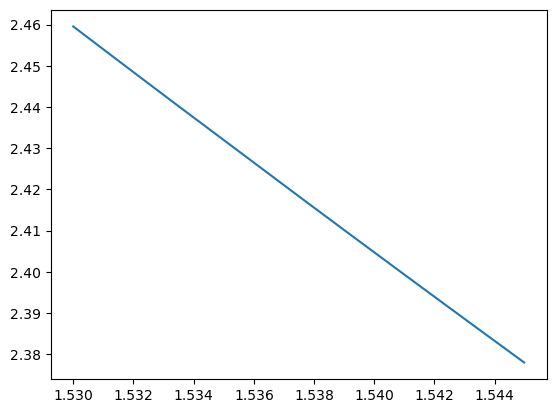

In [3]:
plt.plot(dat["col1"], dat["col3"])

In [4]:
%matplotlib notebook
tr_cfht = astropy.io.ascii.read("../spec_h_norm.txt.1530")
plt.plot(tr_cfht["col1"], tr_cfht["col2"])

<IPython.core.display.Javascript object>

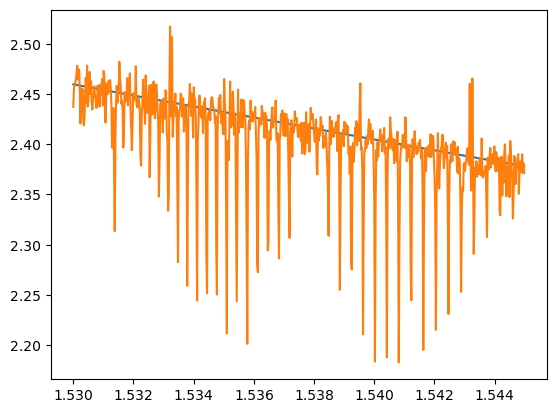

In [5]:
%matplotlib inline
tr_cfht_interp = np.interp(dat["col1"], tr_cfht["col1"], tr_cfht["col2"])
plt.plot(dat["col1"], dat["col3"])
plt.plot(dat["col1"], dat["col3"] * tr_cfht_interp)

In [6]:
wav = dat["col1"]
flx = dat["col3"] * tr_cfht_interp
err = np.max(flx) / 5e2

In [7]:
with open("spec_input_psg.txt.1530", "wb") as f:
    for i in np.arange(len(wav)):
#         print(wav[i], flx[i], err)
        f.write(bytes("{0:20.8f}{1:20.8e}{2:20.8e}\n".format(wav[i], flx[i], err), 'UTF-8'))

In [10]:
tab = astropy.io.ascii.read("JHK_transmittance/psg_trn.txt")